# Lab 3: Regression Models for Ticket Resolution Time

**Name:** Mekdelawit Alemayehu
**ID:** UGR/9271/16

Goal: estimate resolution_hours for software support tickets and compare a mean baseline, linear regression, polynomial regression, Ridge and Lasso on a synthetic dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings; warnings.filterwarnings("ignore")

RANDOM_STATE = 42


## Task 1: Load and inspect the data

In [2]:
df = pd.read_csv("lab_ticket_resolution.csv")
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())

Shape: (240, 6)

Data types:
 ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

Missing values:
 ticket_id                0
complexity_score         0
lines_changed            0
team_experience_years    0
reopened                 0
resolution_hours         0
dtype: int64


In [3]:
df.describe(include="all")

,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
count,240,240.000000,240.000000,240.000000,240.000000,240.000000
unique,240,NaN,NaN,NaN,NaN,NaN
top,T0001,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN
mean,NaN,5.491667,54.820833,6.105417,0.233333,19.361125
std,NaN,2.979697,26.145017,3.391426,0.423836,10.035058
min,NaN,1.000000,1.000000,0.500000,0.000000,0.500000
25%,NaN,3.000000,33.000000,3.300000,0.000000,11.015000
50%,NaN,5.500000,54.000000,5.800000,0.000000,19.610000
75%,NaN,8.000000,74.000000,9.200000,0.000000,27.122500


In [4]:
df.head()

,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


In [5]:
df.drop(columns="ticket_id").corr().round(3)

,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
complexity_score,1.000,0.913,-0.069,0.151,0.918
lines_changed,0.913,1.000,-0.043,0.103,0.847
team_experience_years,-0.069,-0.043,1.000,0.028,-0.175
reopened,0.151,0.103,0.028,1.000,0.301
resolution_hours,0.918,0.847,-0.175,0.301,1.000


**Observations:**
- The dataset has 240 rows and 6 columns, with no missing values.
- complexity_score has the strongest link to resolution time (0.92): harder tickets take longer.
- lines_changed is also strongly linked (0.85), but it is almost a copy of complexity (0.91), so it adds little new information.
- reopened has a moderate positive link (0.30), and team_experience_years has a weak negative link (-0.18): more experienced teams are slightly faster.

In [6]:
FEATURES = ["complexity_score", "team_experience_years"]

X = df[FEATURES]
y = df["resolution_hours"]

print(X.shape, y.shape)


(240, 2) (240,)


## Task 2: Choosing features

**Prediction time:** when a ticket is first opened, before work starts.

- ticket_id: **excluded**. It is an identifier and carries no information about the ticket.
- complexity_score: **used**. It is estimated when the ticket is opened.
- team_experience_years: **used**. It is known once the ticket is assigned.
- lines_changed: **excluded (leakage)**. It is only known after the fix is done.
- reopened: **excluded (leakage)**. A ticket can only be reopened after it has been closed.

Using lines_changed or reopened would make the model look better than it really is, because it would be using information that doesn't exist yet at prediction time.

## Task 3: Train/test split

- 80% training (192 rows), 20% test (48 rows), with random_state=42 so the split is reproducible.
- All model choices (polynomial degree, alpha) are made with **5-fold cross-validation on the training set only**.
- The test set is used **once at the end** to report final results. It is never used to pick model settings.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)

# 5-fold cross-validation, used ONLY on the training set to compare models
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


Train: (192, 2)  Test: (48, 2)


In [8]:
def test_metrics(model, name):
    """Score a fitted model on the test set."""
    pred = model.predict(X_test)
    return {"model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred)}

def cv_metrics(model, name):
    """Score a model with 5-fold cross-validation on the training set."""
    s = cross_validate(model, X_train, y_train, cv=cv, return_train_score=True,
                       scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
    return {"model": name,
            "CV MAE": -s["test_neg_mean_absolute_error"].mean(),
            "CV RMSE": -s["test_neg_root_mean_squared_error"].mean(),
            "CV RMSE std": s["test_neg_root_mean_squared_error"].std(),
            "Train RMSE": -s["train_neg_root_mean_squared_error"].mean(),
            "CV R2": s["test_r2"].mean()}

results, cv_results = [], []   # lists to collect scores for every model


In [9]:
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)

cv_results.append(cv_metrics(DummyRegressor(strategy="mean"), "Baseline (mean)"))
results.append(test_metrics(dummy, "Baseline (mean)"))

pd.DataFrame(results).round(3)


,model,MAE,RMSE,R2
0,Baseline (mean),9.114,10.598,-0.021


## Task 4: Baseline

The mean baseline always predicts the average training resolution time and ignores every feature.
Test results: MAE ≈ 9.1 h, RMSE ≈ 10.6 h, R² ≈ 0.
Any useful model must clearly beat these numbers.


In [10]:
lin = make_pipeline(StandardScaler(), LinearRegression())
lin.fit(X_train, y_train)

cv_results.append(cv_metrics(make_pipeline(StandardScaler(), LinearRegression()), "Linear"))
results.append(test_metrics(lin, "Linear"))

pd.DataFrame(results).round(3)


,model,MAE,RMSE,R2
0,Baseline (mean),9.114,10.598,-0.021
1,Linear,2.906,3.572,0.884


In [11]:
lin_raw = LinearRegression().fit(X_train, y_train)
print("Start value (intercept):", round(lin_raw.intercept_, 2))
print(pd.Series(lin_raw.coef_, index=FEATURES).round(2))


Start value (intercept): 4.25
complexity_score         3.08
team_experience_years   -0.32
dtype: float64


## Task 5: Linear regression

Test results: MAE ≈ 2.9 h, RMSE ≈ 3.6 h, R² ≈ 0.88, much better than the baseline (MAE ≈ 9.1 h).
Each extra complexity point adds about 3 hours. Each extra year of team experience saves about 0.3 hours.

In [12]:
poly_models = {}
for d in [2, 3]:
    pipe = make_pipeline(PolynomialFeatures(degree=d, include_bias=False),
                         StandardScaler(),
                         LinearRegression())
    cv_results.append(cv_metrics(pipe, f"Poly deg {d}"))
    poly_models[d] = pipe.fit(X_train, y_train)

pd.DataFrame(cv_results).set_index("model").round(3)


,CV MAE,CV RMSE,CV RMSE std,Train RMSE,CV R2
model,,,,,
Baseline (mean),8.448,9.884,0.754,9.863,-0.023
Linear,3.168,3.909,0.411,3.860,0.838
Poly deg 2,3.131,3.832,0.461,3.758,0.844
Poly deg 3,3.162,3.877,0.314,3.681,0.841


In [13]:
for d in [2, 3]:
    results.append(test_metrics(poly_models[d], f"Poly deg {d}"))

pd.DataFrame(results).set_index("model").round(3)


,MAE,RMSE,R2
model,,,
Baseline (mean),9.114,10.598,-0.021
Linear,2.906,3.572,0.884
Poly deg 2,3.020,3.741,0.873
Poly deg 3,3.140,3.949,0.858


## Task 6: Polynomial degree 2 vs 3

- Training error falls as the degree rises (3.86 → 3.76 → 3.68), but cross-validation error barely changes (3.91 → 3.83 → 3.88).
- Degree 2's improvement (0.08 h) is smaller than the fold to fold variation (std ≈ 0.4), so it is not a real gain.
- The growing gap between training and CV error is a sign of overfitting: the extra terms fit noise, not real patterns.
- On the test set, both polynomial models are slightly worse than linear regression.
- Conclusion: the simple straight-line model is enough for this data.


In [14]:
ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    {"ridge__alpha": np.logspace(-3, 3, 25)},     # 25 values from 0.001 to 1000
    cv=cv, scoring="neg_root_mean_squared_error").fit(X_train, y_train)

lasso_search = GridSearchCV(
    make_pipeline(StandardScaler(), Lasso(max_iter=10000)),
    {"lasso__alpha": np.logspace(-3, 1, 25)},     # 25 values from 0.001 to 10
    cv=cv, scoring="neg_root_mean_squared_error").fit(X_train, y_train)

ridge = ridge_search.best_estimator_
lasso = lasso_search.best_estimator_

print("Best Ridge alpha:", round(ridge_search.best_params_["ridge__alpha"], 4))
print("Best Lasso alpha:", round(lasso_search.best_params_["lasso__alpha"], 4))

cv_results.append(cv_metrics(ridge, "Ridge"))
cv_results.append(cv_metrics(lasso, "Lasso"))
results.append(test_metrics(ridge, "Ridge"))
results.append(test_metrics(lasso, "Lasso"))


Best Ridge alpha: 0.5623
Best Lasso alpha: 0.001


In [15]:
coef = pd.DataFrame({
    "Linear": lin[-1].coef_,
    "Ridge": ridge[-1].coef_,
    "Lasso": lasso[-1].coef_}, index=FEATURES)
coef.round(4)


,Linear,Ridge,Lasso
complexity_score,8.9948,8.9686,8.9938
team_experience_years,-1.0778,-1.0752,-1.0768


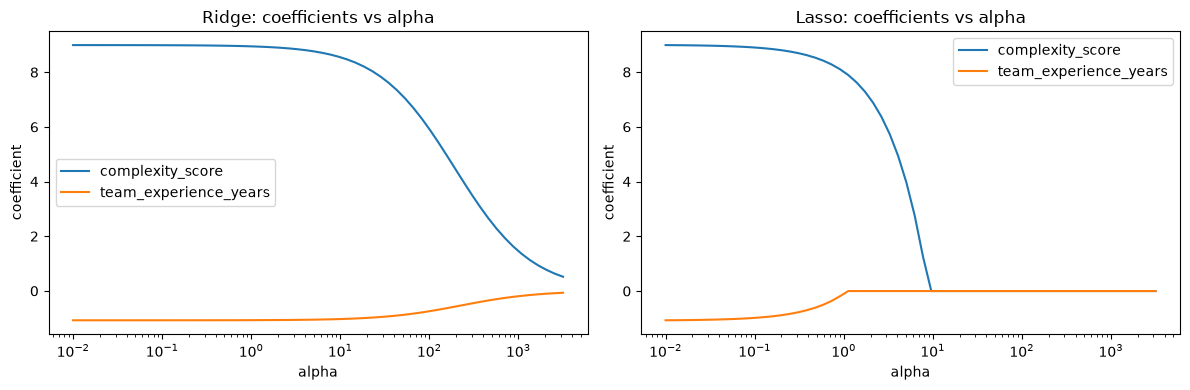

In [16]:
alphas = np.logspace(-2, 3.5, 60)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, M, name in [(axes[0], Ridge, "Ridge"), (axes[1], Lasso, "Lasso")]:
    paths = [make_pipeline(StandardScaler(), M(alpha=a, max_iter=10000))
             .fit(X_train, y_train)[-1].coef_ for a in alphas]
    ax.plot(alphas, paths, label=FEATURES)
    ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.set_ylabel("coefficient")
    ax.set_title(f"{name}: coefficients vs alpha"); ax.legend()
plt.tight_layout(); plt.show()


## Task 7: Ridge and Lasso

- Alpha was chosen with 5-fold CV on the training set: Ridge alpha ≈ 0.56, Lasso alpha = 0.001.
- Lasso's best alpha is the smallest value in the grid, which means CV wanted almost no penalty.
- Coefficients and errors are almost identical to plain linear regression.
- Regularization did not help because there are only 2 features and 192 rows, so the linear model is not overfitting.
- Scaling is included because the penalty depends on coefficient size, and without scaling, features measured in different units would be penalised unfairly.
- **Coefficient paths:** as alpha grows, Ridge shrinks both coefficients smoothly toward 0 but never reaches it. Lasso sets team_experience_years to exactly 0 first (alpha ≈ 1), because it is the weaker feature, and then complexity_score (alpha ≈ 10). The alphas chosen by CV sit on the flat left part of the curves, so the coefficients are barely shrunk.


In [17]:
cv_df = pd.DataFrame(cv_results).set_index("model")
test_df = pd.DataFrame(results).set_index("model")

print("Cross-validation (training set), used to CHOOSE a model:")
display(cv_df.round(3))
print("Test set, used only to REPORT the final result:")
display(test_df.round(3))


Cross-validation (training set), used to CHOOSE a model:


,CV MAE,CV RMSE,CV RMSE std,Train RMSE,CV R2
model,,,,,
Baseline (mean),8.448,9.884,0.754,9.863,-0.023
Linear,3.168,3.909,0.411,3.860,0.838
Poly deg 2,3.131,3.832,0.461,3.758,0.844
Poly deg 3,3.162,3.877,0.314,3.681,0.841
Ridge,3.168,3.909,0.414,3.860,0.838
Lasso,3.168,3.909,0.411,3.860,0.838


Test set, used only to REPORT the final result:


,MAE,RMSE,R2
model,,,
Baseline (mean),9.114,10.598,-0.021
Linear,2.906,3.572,0.884
Poly deg 2,3.020,3.741,0.873
Poly deg 3,3.140,3.949,0.858
Ridge,2.906,3.571,0.884
Lasso,2.906,3.572,0.884


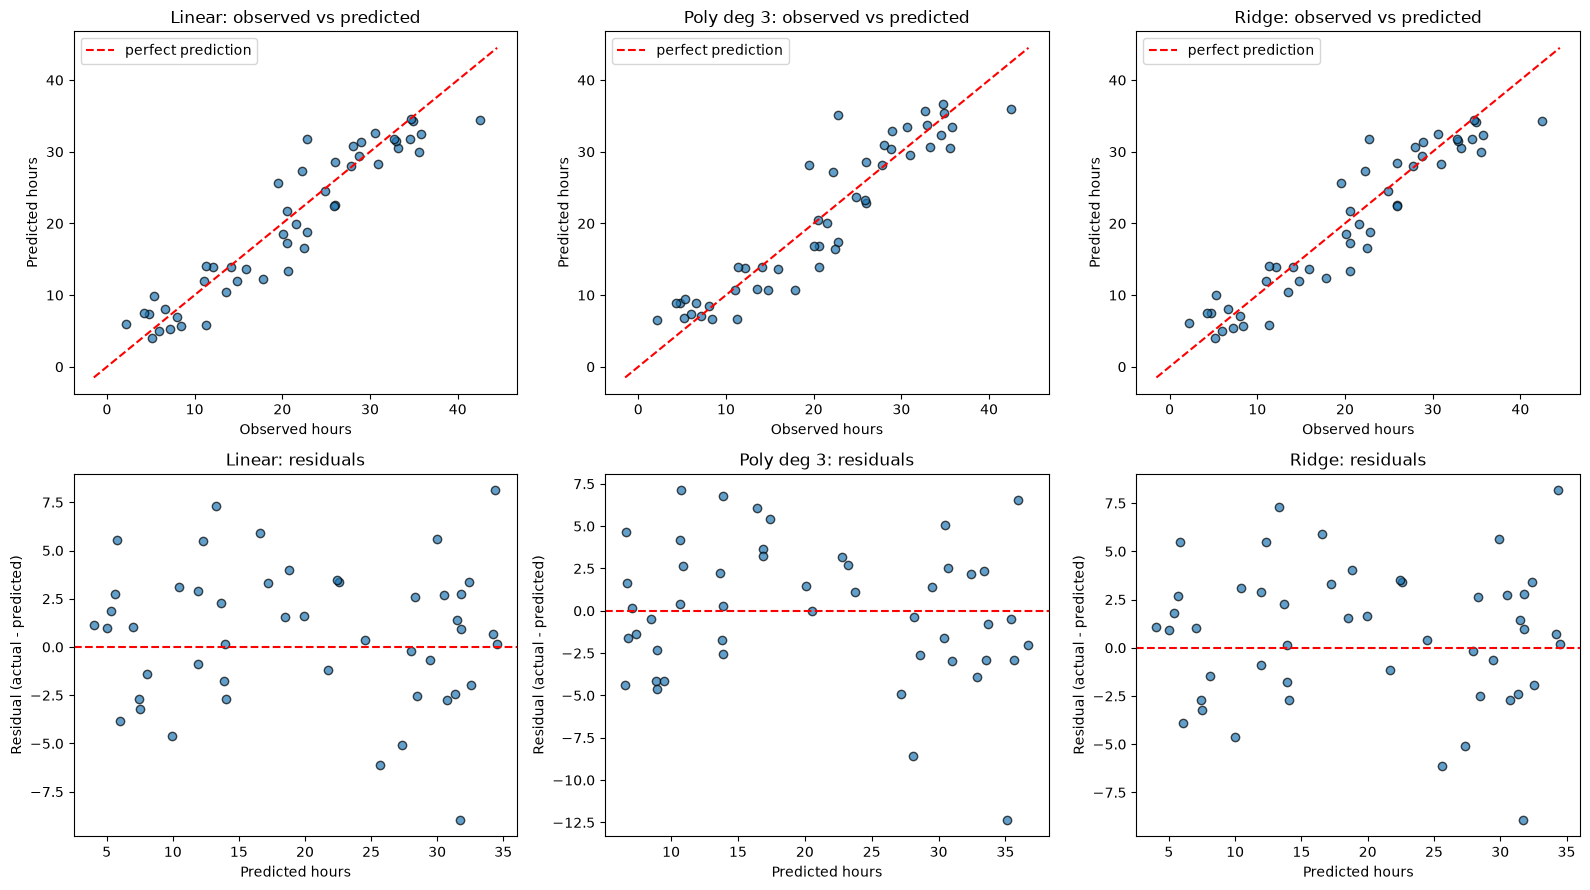

In [18]:
plot_models = {"Linear": lin, "Poly deg 3": poly_models[3], "Ridge": ridge}
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
lims = [y.min() - 2, y.max() + 2]

for i, (name, m) in enumerate(plot_models.items()):
    pred = m.predict(X_test)
    resid = y_test - pred

    # Top row: observed vs predicted
    ax = axes[0, i]
    ax.scatter(y_test, pred, alpha=0.7, edgecolor="k")
    ax.plot(lims, lims, "r--", label="perfect prediction")
    ax.set_xlabel("Observed hours"); ax.set_ylabel("Predicted hours")
    ax.set_title(f"{name}: observed vs predicted"); ax.legend()

    # Bottom row: residuals
    ax = axes[1, i]
    ax.scatter(pred, resid, alpha=0.7, edgecolor="k")
    ax.axhline(0, color="r", ls="--")
    ax.set_xlabel("Predicted hours"); ax.set_ylabel("Residual (actual - predicted)")
    ax.set_title(f"{name}: residuals")

plt.tight_layout(); plt.show()


In [19]:
out = X_test.assign(actual=y_test,
                    predicted=lin.predict(X_test).round(2),
                    error=(y_test - lin.predict(X_test)).round(2))
out.reindex(out.error.abs().sort_values(ascending=False).index).head(5)


,complexity_score,team_experience_years,actual,predicted,error
55,9,0.7,22.78,31.75,-8.97
16,10,2.1,42.50,34.38,8.12
24,3,0.6,20.62,13.30,7.32
192,7,0.5,19.52,25.65,-6.13
114,5,9.7,22.49,16.56,5.93


## Task 8: Plots

- **Observed vs predicted:** points follow the diagonal closely for all models, so predictions are generally accurate.
- **Curvature:** none. The residuals scatter randomly around 0, so a straight line is a good fit.
- **Changing spread:** none clear. The spread of the residuals is about the same for small and large predictions (no funnel shape).
- **Outliers:** a few tickets are off by 6–9 hours, but they don't pull the model noticeably.
- Linear and Ridge give identical plots, and Poly deg 3 looks almost the same, so the extra complexity doesn't capture anything new.


## Task 9: Recommendation

**Chosen model: Linear regression** using complexity_score and team_experience_years.

**Evidence (from cross-validation on the training set):**
- It reduces error far below the baseline: CV MAE ≈ 3.2 h vs ≈ 8.4 h for the mean baseline.
- Polynomial degree 2 improved CV RMSE by only 0.08 h, less than the fold-to-fold variation (std ≈ 0.4), so it is not a real gain. Degree 3 showed signs of overfitting: training error fell while CV error did not improve.
- Ridge and Lasso chose very small alphas and gave the same coefficients and errors as linear regression, so regularization added nothing.
- The residual plots show no curvature and no funnel shape, so a straight line fits well.
- It is the simplest model to explain: each complexity point adds about 3 hours, and each year of team experience saves about 0.3 hours.

**Confirmation on the test set:** linear regression got MAE ≈ 2.9 h, RMSE ≈ 3.6 h, R² ≈ 0.88. It was at least as good as every other model, and better than both polynomial models.

**Further data and checks needed:**
- Real (not synthetic) ticket data with dates, so the model can be tested on newer tickets after training on older ones.
- More features known when a ticket opens: ticket type, priority, product area, customer, description text.
- A check on how reliable complexity_score is, since it drives most of the prediction and is someone's estimate.
- A range instead of a single number (e.g. "15–22 hours"), because the typical error is about ±3–4 hours.


## Analysis questions

**10. Why is the mean baseline useful even though it ignores all features?**

The baseline just guesses the average resolution time for every ticket. It's the "no effort" answer, so any real model has to beat it to be worth using. Our baseline was off by about 9 hours on average, and linear regression brought that down to about 3 hours. That big drop shows the features actually help. If a model ever scored about the same as the baseline, I'd know something was wrong.

**11. Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they differ?**

On the test set, Linear, Ridge and Lasso tie for both the lowest MAE (≈ 2.91 h) and the lowest RMSE (≈ 3.57 h), so here the winner is the same for both. But that doesn't always happen. MAE treats every hour of error the same. RMSE squares the errors first, so one big miss hurts it a lot more. A model that's usually very close but occasionally way off could win on MAE and lose on RMSE.

**12. Did polynomial features improve validation performance? What is the evidence of possible overfitting?**

Not really. Degree 2 lowered CV RMSE by only about 0.08 hours, which is smaller than how much the score already jumps around between folds (about 0.4). Degree 3 didn't help at all. The sign of overfitting is that training error kept going down as I added more terms (3.86 → 3.76 → 3.68), but the CV error stayed flat. The model was getting better at the data it had already seen, not at new data. On the test set, both polynomial models were actually worse than plain linear regression.

**13. How did regularization affect performance and coefficient magnitudes?**

At the alphas chosen by CV, almost nothing changed. The coefficients and errors were nearly the same as linear regression. The coefficient plots show what happens with a stronger penalty: Ridge slowly shrinks both coefficients toward 0 but never gets there, while Lasso pushes team_experience_years to exactly 0 first (the weaker feature) and later complexity_score too. Regularization didn't help here because we only have 2 features and 192 rows, so the linear model wasn't overfitting in the first place.

**14. Why is scaling included in the Ridge/Lasso pipeline?**

The penalty punishes big coefficients, but how big a coefficient is depends on the feature's units. Without scaling, some features would get punished more just because of how they're measured. Scaling puts all features on the same footing, so the penalty is fair. It's inside the pipeline so the scaler only learns from the training part of each fold, so no information from the validation or test data sneaks in.

**15. Identify one potential leakage issue in the dataset and explain how you handled it.**

lines_changed is the number of lines changed during the fix, so we only know it after the work is done. When a ticket first comes in, that number doesn't exist yet. reopened has the same problem, because a ticket can only be reopened after it's closed. I removed both from the features and only used what's known when the ticket opens: complexity_score and team_experience_years. If I had kept them, the model would look better in the lab than it could ever be in real life. The leakage check below shows this: adding lines_changed changes nothing (it is almost a copy of complexity), while adding reopened makes the scores look better even though that information isn't available when the ticket opens.

**16. Would a random split be appropriate if tickets were collected over several years or came from repeated customers/teams? Explain.**

No. If tickets span several years, a random split lets the model train on newer tickets and get tested on older ones, which is like seeing the future. It also hides changes over time, like new tools or new staff. A better choice is to train on older tickets and test on newer ones. If the same customers or teams show up again and again, a random split puts them in both training and test, so the model looks better than it would on a brand-new customer. In that case I'd split by customer or team so each one only appears on one side.

**17. What additional tests would you perform before deploying this model?**

- Test it on real ticket data, split by time (older tickets for training, newer for testing).
- Check whether it is much worse for certain kinds of tickets, teams or products.
- Give a range instead of one number (e.g. "15–22 hours"), since it's usually off by about 3–4 hours.
- See what happens when complexity_score is estimated badly or is missing.
- Run it quietly alongside the current manual estimates for a while before anyone relies on it.
- After launch, keep watching its errors over time and retrain it when performance drops.

### Leakage check: what if the excluded features were used?

In [20]:
for extra in ["lines_changed", "reopened"]:
    cols = FEATURES + [extra]
    m = LinearRegression().fit(df.loc[X_train.index, cols], y_train)
    p = m.predict(df.loc[X_test.index, cols])
    print(f"+ {extra}: MAE = {mean_absolute_error(y_test, p):.3f}, R2 = {r2_score(y_test, p):.3f}")

+ lines_changed: MAE = 2.906, R2 = 0.884
+ reopened: MAE = 2.591, R2 = 0.906
